# Version 3 — Research-Informed Deep Learning
## Bahrain Rental Price Prediction
**Research question:** Can richer property information and learned categorical representations reduce MAE compared with the doctor's three-input neural network?

Run top to bottom. Put `property_data.csv` (or `data.csv`) and `test.csv` beside this notebook or in `data/`. Dependencies: Python, tensorflow, scikit-learn, pandas, numpy, matplotlib, seaborn, joblib. All imports are in the first code cell. The notebook trains models and produces `submission_version3_research.csv`.

This is a research-informed adaptation, not a replication of either paper. Version 1 already tried embeddings; Version 3 supplies the literature rationale and a controlled comparison on Version 2's rows and split. No score below 70 is assumed.

## 1. Research and connection to this project
**Main related-topic paper:** Yang, Y., Dai, H.-M., Chao, C.-H., Wei, S., & Yang, C.-F. (2023). *Training a Neural Network to Predict House Rents Using Artificial Intelligence and Deep Learning*. Sensors and Materials, 35(10), 4671–4680. [DOI](https://doi.org/10.18494/SAM4594) · [Full paper](https://sensors.myu-group.co.jp/sm_pdf/SM3421.pdf).

The study uses 689 Taipei listings, with floorspace, floor and permission indicators. Sections 2.3–2.5 describe separate training/validation/test data, training-only standardization, target normalization, and a Keras neural network. It is directly related to rent regression, but its small dataset and different market do not establish performance in Bahrain.

**Supporting method paper:** Guo, C., & Berkhahn, F. (2016). *Entity Embeddings of Categorical Variables*. arXiv:1604.06737. [Paper](https://arxiv.org/abs/1604.06737) · [Full text](https://arxiv.org/html/1604.06737v1).

This paper learns categorical vectors jointly with supervised neural-network training. Its application is retail sales, not housing. We test whether this transferable representation helps with Bahrain location and property categories.

| Research idea | Implementation here | Attribution / difference |
|---|---|---|
| Numeric normalization and separate evaluation sets | Fit scaler on training rows; preserve Version 2 splits | Related rent paper; exact row splits come from our lecture baseline |
| Target normalization | Divide rent by 500, restore BHD for every score | Our constant-scale adaptation, not the paper's maximum scaling |
| Learned category vectors | Keras Embedding layers joined with numerical inputs | Supporting embedding paper; dimensions and architecture are our choices |
| More informative property inputs | Location, furnishings, amenities and structural ratios | Bahrain-specific feature engineering |
| Competition objective | Optimize MAE instead of MSE | Our adaptation to the competition |

**Hypothesis, not a guarantee:** category embeddings may share useful information across categories. An enriched one-hot model is the control, so improvement from extra features is not automatically credited to embeddings.

## 2. Imports and reproducibility
Import every dependency here. A fixed seed helps reproduce this run; TensorFlow versions and hardware may still affect floating-point results.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import re
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, TerminateOnNaN
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

SEED = 42
MAX_EPOCHS = 100
PATIENCE = 12
BATCH_SIZE = 256
TARGET_SCALE = 500.0
OUTPUT_DIR = Path("version3_research_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 3. Load data
The competition test file is unlabeled. Its IDs determine submission order. The old sample template may have different rows, so it is not used to substitute IDs.

In [2]:
def locate(names):
    for folder in [Path("."), Path("data"), Path("../data")]:
        for name in names:
            if (folder / name).exists():
                return folder / name
    raise FileNotFoundError(f"Please provide one of {names}")
raw = pd.read_csv(locate(["property_data.csv", "data.csv"]))
test_raw = pd.read_csv(locate(["test.csv"]))
print("Labeled:", raw.shape, "Unlabeled:", test_raw.shape)
display(raw.head(3))

Labeled: (32090, 41) Unlabeled: (3566, 40)


,Unnamed: 0,Property_id,property_type,offer,governorate,bedrooms,bathrooms,rent,location,city,...,is_super_agent,broker_id,floor_plans,is_featured,is_premium,description,is_verified,is_verified.1,is_exclusive,is_exclusive.1
0,27387,7343b863-a2cb-4d85-b2dd-935ea61365ff,Apartment,Residential for Rent,"Capital Governorate, Manama",studio,1,245.0,NaN,NaN,...,True,1031.0,NaN,False,False,A different furnished studio opportunity in Sa...,False,False,False,False
1,18554,f1a36ab5-1601-4127-a7a7-5095f167acca,Apartment,Rent,Capital Governorate,1,1,300.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9295,bf629ae9-a3b2-4c2e-8e0e-b0ffce916fa7,Compound,Rent,Northern Governorate,5,5,1200.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Feature preparation and matching Version 2
Use exactly Version 2's room and area parsing and complete-case eligibility for the controlled experiment. Targets are never capped or removed for being expensive. Preserve original row indices.

In [3]:
def parse_rooms(value):
    if pd.isna(value):
        return np.nan
    text = str(value).lower()
    if "studio" in text:
        return 0.0
    match = re.search(r"\d+", text)
    return float(match.group()) if match else np.nan

def parse_area(value):
    if pd.isna(value):
        return np.nan
    text = str(value).replace(",", "").lower().strip()
    match = re.search(r"(\d+(?:\.\d+)?)\s*sqm", text)
    if match:
        result = float(match.group(1))
    else:
        match = re.search(r"(\d+(?:\.\d+)?)\s*sqft", text)
        if match:
            result = float(match.group(1)) * 0.09290304
        else:
            try:
                result = float(text)
            except ValueError:
                return np.nan
    return result if np.isfinite(result) and result > 0 else np.nan


base = pd.DataFrame({
    "bedrooms_num": raw["bedrooms"].map(parse_rooms),
    "bathrooms_num": raw["bathrooms"].map(parse_rooms),
    "area_sqm_num": raw["area_sqm"].map(parse_area),
    "rent": pd.to_numeric(raw["rent"], errors="coerce")
}).replace([np.inf, -np.inf], np.nan).dropna()
train = raw.loc[base.index].copy()
y = base["rent"]
base_x = base.drop(columns="rent")
train_full_idx, holdout_idx = train_test_split(base.index.to_numpy(), test_size=.2, random_state=42)
train_idx, val_idx = train_test_split(train_full_idx, test_size=.25, random_state=42)
assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(holdout_idx)
assert set(val_idx).isdisjoint(holdout_idx)
print("Complete rows:", len(base), "Excluded incomplete rows:", len(raw)-len(base))
print("Train / validation / holdout:", len(train_idx), len(val_idx), len(holdout_idx))
splits = pd.Series("train", index=base.index)
splits.loc[val_idx] = "validation"
splits.loc[holdout_idx] = "holdout"
pd.DataFrame({"Property_id": train["Property_id"], "split": splits}).to_csv(OUTPUT_DIR / "split_assignments.csv", index=False)

Complete rows: 32075 Excluded incomplete rows: 15
Train / validation / holdout: 19245 6415 6415


## 5. EDA — inspect training rows only
Summarize missingness and raw training rents. The log axis makes expensive properties visible without changing training labels. Random row splits match Version 2; duplicate URLs may cross splits. Count this limitation without using holdout targets for model selection.

price_per_sqm        1.000000
completion_status    1.000000
floor_plans          1.000000
down_payment         1.000000
payment_methods      0.993089
plot_size_sqm        0.924500
location             0.909951
city                 0.747415
availability_date    0.715770
agency               0.701793
furnished            0.551260
is_premium           0.550792
Name: missing_fraction, dtype: float64

count     19245.000000
mean        679.334269
std        7673.569554
min          80.000000
50%         450.000000
95%        1380.000000
99%        1878.000000
99.9%      4878.000000
max      950000.000000
Name: rent, dtype: float64

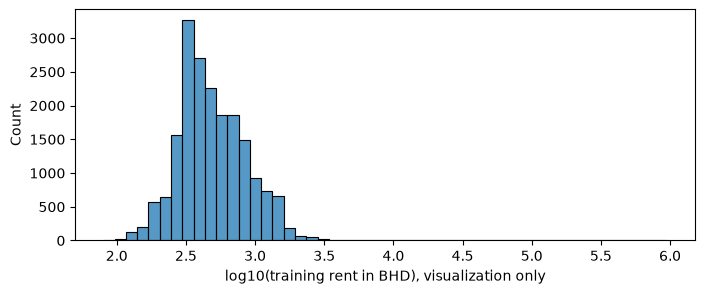

validation rows sharing a URL with training: 141
holdout rows sharing a URL with training: 141


In [4]:
display(raw.loc[train_idx].isna().mean().sort_values(ascending=False).head(12).rename("missing_fraction"))
display(y.loc[train_idx].describe(percentiles=[.5, .95, .99, .999]))
plt.figure(figsize=(8, 3))
sns.histplot(np.log10(y.loc[train_idx].clip(lower=1)), bins=50)
plt.xlabel("log10(training rent in BHD), visualization only")
plt.show()
train_urls = set(raw.loc[train_idx, "URL"].dropna().astype(str))
for name, idx in [("validation", val_idx), ("holdout", holdout_idx)]:
    overlap = raw.loc[idx, "URL"].notna() & raw.loc[idx, "URL"].astype(str).isin(train_urls)
    print(name, "rows sharing a URL with training:", int(overlap.sum()))

## 6. Feature engineering
Use structural ratios, coordinates, amenity indicators, fixed title keywords and categorical listing attributes. No raw price-bearing title or description, target encoding, `price_per_sqm`, ID or URL enters the model. The geographic distance is an approximate engineered input, not a paper result. Category labels are normalized consistently.

These are existing Version 1 feature ideas reused for a fair research experiment; the literature does not prescribe this exact list.

In [5]:
def clean_text(series):
    return (series.fillna("").astype(str).str.lower().str.strip()
            .str.replace(r"\s+", " ", regex=True).replace("", "__missing__"))

AMENITIES = {
    "pool": "pool", "private_pool": "private pool", "gym": "gym",
    "security": "security", "concierge": "concierge", "balcony": "balcony",
    "garden": "garden", "maid_service": "maid service", "maids_room": "maid",
    "sea_view": "view of water|sea view", "central_ac": "central a/c|central ac",
    "kitchen": "kitchen appliances", "parking": "parking", "study": "study",
    "wardrobes": "wardrobes", "children": "children", "beach": "beach"
}
TITLE_TERMS = {"luxury": "luxury", "new": "brand new", "sea_view": "sea view",
               "spacious": "spacious", "maid": "maid", "balcony": "balcony",
               "pool": "pool", "garden": "garden"}
CAT_COLS = ["property_type", "governorate_main", "neighborhood", "city", "location",
            "location_full", "furnished", "include_w_e", "period", "offer", "agency"]

def engineer_features(raw):
    def col(name):
        return raw[name] if name in raw else pd.Series(np.nan, index=raw.index)
    out = pd.DataFrame(index=raw.index)
    out["area_sqm_num"] = col("area_sqm").map(parse_area)
    out["bedrooms_num"] = col("bedrooms").map(parse_rooms)
    out["bathrooms_num"] = col("bathrooms").map(parse_rooms)
    out["maid_room"] = clean_text(col("bedrooms")).str.contains("maid", regex=False).astype(float)
    out["log_area"] = np.log1p(out["area_sqm_num"])
    out["area_per_bedroom"] = out["area_sqm_num"] / (out["bedrooms_num"] + 1)
    out["baths_per_bedroom"] = out["bathrooms_num"] / (out["bedrooms_num"] + 1)
    lat = pd.to_numeric(col("latitude"), errors="coerce")
    lon = pd.to_numeric(col("longitude"), errors="coerce")
    geo_ok = lat.between(25, 27) & lon.between(49, 52)
    out["latitude"], out["longitude"] = lat.where(geo_ok), lon.where(geo_ok)
    out["has_geo"] = geo_ok.astype(float)
    out["distance_manama_km"] = np.sqrt(((out["latitude"] - 26.2285) * 111)**2 +
                                           ((out["longitude"] - 50.5860) * 102)**2)
    amen = clean_text(col("amenities"))
    has_text = ~amen.eq("__missing__") & ~amen.str.fullmatch(r"[\d\s,.]+", na=False)
    out["amenity_text_available"] = has_text.astype(float)
    out["amenity_count"] = amen.str.split(",").str.len().where(has_text, 0).astype(float)
    for name, pattern in AMENITIES.items():
        out["has_" + name] = (has_text & amen.str.contains(pattern, regex=True)).astype(float)
    title = clean_text(col("title"))
    for name, pattern in TITLE_TERMS.items():
        out["title_" + name] = title.str.contains(pattern, regex=False).astype(float)
    for name in ["is_featured", "is_premium", "is_super_agent", "is_verified"]:
        out[name + "_flag"] = clean_text(col(name)).map({"true":1., "false":0., "1":1., "0":0., "yes":1., "no":0.})
    for name in CAT_COLS:
        if name not in ["governorate_main", "neighborhood"]:
            out[name] = clean_text(col(name))
    gov = clean_text(col("governorate"))
    out["governorate_main"] = gov.str.split(",").str[0].str.strip()
    out["neighborhood"] = gov.map(lambda s: s.split(",", 1)[1].strip() if "," in s else "__missing__")
    return out.replace([np.inf, -np.inf], np.nan)

X = engineer_features(train)
competition_X = engineer_features(test_raw).reindex(columns=X.columns)
NUM_COLS = [c for c in X if c not in CAT_COLS]
assert not {"rent", "price_per_sqm", "Property_id", "URL", "description"}.intersection(X.columns)
print("Numeric / categorical:", len(NUM_COLS), len(CAT_COLS))
display(X.head(3))

Numeric / categorical: 42 11


,area_sqm_num,bedrooms_num,bathrooms_num,maid_room,log_area,area_per_bedroom,baths_per_bedroom,latitude,longitude,has_geo,...,city,location,location_full,furnished,include_w_e,period,offer,agency,governorate_main,neighborhood
0,43.0,0.0,1.0,0.0,3.784190,43.000000,1.000000,26.226559,50.54591,1.0,...,__missing__,__missing__,"sanabis, manama, capital governorate",yes,inclusive,monthly,residential for rent,__missing__,capital governorate,manama
1,65.0,1.0,1.0,0.0,4.189655,32.500000,0.500000,NaN,NaN,0.0,...,__missing__,__missing__,__missing__,__missing__,inclusive,__missing__,rent,deccan real estate,capital governorate,__missing__
2,400.0,5.0,5.0,0.0,5.993961,66.666667,0.833333,NaN,NaN,0.0,...,__missing__,__missing__,__missing__,__missing__,exclusive,__missing__,rent,aqaratcom for real estate,northern governorate,__missing__


## 7. Training-only preprocessing
Clip numerical inputs at training 0.5th/99.5th percentiles, impute training medians, standardize, and append missingness flags. This bounds inputs only, never rents. This clipping is our robustness choice, not a result from either paper.

Build categorical vocabularies using training rows only. Rare labels (fewer than three observations) and unknown labels share index zero. Both one-hot and embedding candidates receive the same category IDs; only their representation differs.

In [6]:
def fit_preprocessor(frame):
    numeric = frame[NUM_COLS].astype(float).replace([np.inf, -np.inf], np.nan)
    lower, upper = numeric.quantile(.005), numeric.quantile(.995)
    bounded = numeric.clip(lower=lower, upper=upper, axis=1)
    medians = bounded.median().fillna(0.)
    scaler = StandardScaler().fit(bounded.fillna(medians))
    vocab = {}
    for c in CAT_COLS:
        counts = frame[c].value_counts()
        kept = sorted(counts[counts >= 3].index.tolist())
        vocab[c] = {value: i+1 for i, value in enumerate(kept)}
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
    cat_ids = np.column_stack([frame[c].map(vocab[c]).fillna(0).astype("int32") for c in CAT_COLS])
    enc.fit(cat_ids)
    return {"lower":lower, "upper":upper, "medians":medians, "scaler":scaler,
            "vocab":vocab, "onehot":enc, "numeric_columns":NUM_COLS, "categorical_columns":CAT_COLS}

def transform_features(frame, prep):
    numeric = frame[prep["numeric_columns"]].astype(float).replace([np.inf, -np.inf], np.nan)
    missing = numeric.isna().to_numpy(dtype=np.float32)
    bounded = numeric.clip(lower=prep["lower"], upper=prep["upper"], axis=1)
    scaled = prep["scaler"].transform(bounded.fillna(prep["medians"]))
    numeric_array = np.concatenate([scaled, missing], axis=1).astype(np.float32)
    ids = np.column_stack([frame[c].map(prep["vocab"][c]).fillna(0).to_numpy(dtype=np.int32) for c in CAT_COLS])
    basic = np.concatenate([numeric_array, prep["onehot"].transform(ids)], axis=1).astype(np.float32)
    embedded = {"numeric":numeric_array, **{f"cat_{j}":ids[:, j:j+1] for j in range(len(CAT_COLS))}}
    assert np.isfinite(basic).all()
    return {"basic":{"features":basic}, "embedding":embedded}

prep = fit_preprocessor(X.loc[train_idx])
train_inputs = transform_features(X.loc[train_idx], prep)
val_inputs = transform_features(X.loc[val_idx], prep)
base_scaler = StandardScaler().fit(base_x.loc[train_idx])
base_train = base_scaler.transform(base_x.loc[train_idx]).astype("float32")
base_val = base_scaler.transform(base_x.loc[val_idx]).astype("float32")
print("One-hot width:", train_inputs["basic"]["features"].shape[1])

One-hot width: 489


## 8. Re-run the doctor's baseline
Use the same three features, standardization, 30–20–15 ReLU layers, linear output, Adam(0.01), MSE, 100-epoch limit, batch size 64 and patience 5. We add a seed to make this comparison repeatable. Version 2 did not seed its neural weights, so its historical MAE may differ from this rerun.

In [7]:
keras.utils.set_random_seed(SEED)
doctor = keras.Sequential([layers.Input(shape=(3,)), layers.Dense(30, activation="relu"),
    layers.Dense(20, activation="relu"), layers.Dense(15, activation="relu"), layers.Dense(1)])
doctor.compile(optimizer=Adam(learning_rate=.01), loss="mse")
doctor_history = doctor.fit(base_train, y.loc[train_idx].to_numpy(),
    validation_data=(base_val, y.loc[val_idx].to_numpy()), epochs=100, batch_size=64,
    callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)], verbose=0)
doctor.save(OUTPUT_DIR / "doctor_baseline.keras")
doctor_val_mae = mean_absolute_error(y.loc[val_idx], doctor.predict(base_val, verbose=0).ravel())
print("Doctor baseline validation MAE:", doctor_val_mae)

Doctor baseline validation MAE: 382.5256975621426


## 9. Research models and controlled comparisons
All three candidates use MAE with rent divided by 500, the same 128–64 hidden layers, dropout 0.10, Adam(0.001), batch size 256, seed 42 and stopping rule. Multiplying predictions by 500 restores BHD. Nonnegative prediction clipping is applied consistently to all research candidates.

1. **Numeric MAE:** the same three inputs as the doctor; changes optimization/architecture as a bundle.
2. **Enriched one-hot:** adds engineered and categorical features.
3. **Enriched embeddings:** same features and training settings as one-hot; tests the embedding representation. Parameter counts necessarily differ.

The one-hot versus embedding comparison isolates the representation choice more closely. This is a single-seed experiment, not a statistical proof. We do not credit all baseline improvement to one paper.

In [8]:
def make_dataset(inputs, target=None, training=False, seed=SEED):
    if target is None:
        ds = tf.data.Dataset.from_tensor_slices(inputs)
    else:
        ds = tf.data.Dataset.from_tensor_slices((inputs, np.asarray(target, dtype=np.float32).reshape(-1, 1) / TARGET_SCALE))
    if training:
        ds = ds.shuffle(len(next(iter(inputs.values()))), seed=seed, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    return ds.batch(BATCH_SIZE).with_options(options).prefetch(1)

def predict_bhd(model, inputs):
    pred = model.predict(make_dataset(inputs), verbose=0).reshape(-1) * TARGET_SCALE
    return np.maximum(pred, 0.)

def regression_scores(actual, prediction):
    return {"MAE_BHD":float(mean_absolute_error(actual, prediction)),
            "RMSE_BHD":float(np.sqrt(mean_squared_error(actual, prediction))),
            "R2":float(r2_score(actual, prediction))}

### Define networks
An embedding is a trainable vector lookup for a category. Concatenate all vectors and numerical features before the dense layers. The output bias starts at the training median rent/500. Small L2 penalties and dropout are our regularization choices.

In [9]:
def build_network(config, transformed, prep, target, seed):
    keras.utils.set_random_seed(seed)
    if config["kind"] == "basic":
        inp = keras.Input(shape=(transformed["basic"]["features"].shape[1],), name="features")
        inputs, hidden = {"features":inp}, inp
    else:
        numeric = keras.Input(shape=(transformed["embedding"]["numeric"].shape[1],), name="numeric")
        inputs, pieces = {"numeric":numeric}, [numeric]
        for j, col in enumerate(CAT_COLS):
            size = len(prep["vocab"][col]) + 1
            inp = keras.Input(shape=(1,), dtype="int32", name=f"cat_{j}")
            inputs[f"cat_{j}"] = inp
            dim = min(24, max(2, int(np.sqrt(size)) + 1))
            emb = layers.Embedding(size, dim, embeddings_regularizer=regularizers.l2(1e-6))(inp)
            pieces.append(layers.Flatten()(emb))
        hidden = layers.Concatenate()(pieces)
    for width in config["widths"]:
        hidden = layers.Dense(width, activation="relu", kernel_regularizer=regularizers.l2(1e-5))(hidden)
        hidden = layers.Dropout(config["dropout"])(hidden)
    output = layers.Dense(1, activation="linear", name="scaled_rent",
                          bias_initializer=keras.initializers.Constant(float(np.median(target)/TARGET_SCALE)))(hidden)
    model = keras.Model(inputs=inputs, outputs=output, name=config["name"])
    model.compile(optimizer=Adam(learning_rate=config["learning_rate"], clipnorm=5.0),
                  loss="mae", metrics=[keras.metrics.MeanAbsoluteError(name="mae")])
    return model

CONFIGS = [
    {"name":"numeric_mae", "kind":"basic", "widths":[128,64], "dropout":.10, "learning_rate":.001},
    {"name":"enriched_onehot", "kind":"basic", "widths":[128,64], "dropout":.10, "learning_rate":.001},
    {"name":"enriched_embeddings", "kind":"embedding", "widths":[128,64], "dropout":.10, "learning_rate":.001}
]
def inputs_for(config, rich, numeric):
    return {"basic":{"features":numeric}} if config["name"] == "numeric_mae" else rich

## 10. Train and select using validation MAE
Train the predetermined candidates and save restored best weights. Choose the lowest validation MAE. The holdout is not used for architecture, epoch or model selection. The notebook allows one-hot to win: the experiment tests the research idea rather than assuming success.

In [10]:
results, histories = [], {}
for config in CONFIGS:
    keras.backend.clear_session()
    ti = inputs_for(config, train_inputs, base_train)
    vi = inputs_for(config, val_inputs, base_val)
    model = build_network(config, ti, prep, y.loc[train_idx], SEED)
    history = model.fit(make_dataset(ti[config["kind"]], y.loc[train_idx], training=True),
        validation_data=make_dataset(vi[config["kind"]], y.loc[val_idx]), epochs=MAX_EPOCHS,
        callbacks=[EarlyStopping(monitor="val_mae", patience=PATIENCE, restore_best_weights=True),
                   TerminateOnNaN()], verbose=0)
    hist = pd.DataFrame(history.history)
    pred = predict_bhd(model, vi[config["kind"]])
    row = {"model":config["name"], "validation_MAE_BHD":mean_absolute_error(y.loc[val_idx], pred),
           "best_epoch":int(hist["val_mae"].argmin()+1), "parameters":model.count_params()}
    results.append(row)
    histories[config["name"]] = hist
    model.save(OUTPUT_DIR / (config["name"] + ".keras"))
    hist.to_csv(OUTPUT_DIR / (config["name"] + "_history.csv"), index=False)
    print(row, flush=True)
comparison = pd.DataFrame(results).sort_values("validation_MAE_BHD")
best_name = comparison.iloc[0]["model"]
best_config = next(c for c in CONFIGS if c["name"] == best_name)
best_epochs = int(comparison.iloc[0]["best_epoch"])
comparison.to_csv(OUTPUT_DIR / "validation_comparison.csv", index=False)
display(comparison)
print("Selected using validation only:", best_name)

c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{'model': 'numeric_mae', 'validation_MAE_BHD': 305.4048203002264, 'best_epoch': 35, 'parameters': 8833}


c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{'model': 'enriched_onehot', 'validation_MAE_BHD': 261.6467919293922, 'best_epoch': 36, 'parameters': 71041}


c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{'model': 'enriched_embeddings', 'validation_MAE_BHD': 262.7913633731595, 'best_epoch': 51, 'parameters': 31192}


,model,validation_MAE_BHD,best_epoch,parameters
1,enriched_onehot,261.646792,36,71041
2,enriched_embeddings,262.791363,51,31192
0,numeric_mae,305.404820,35,8833


Selected using validation only: enriched_onehot


### Learning curves
Display MAE in BHD (not regularization-augmented loss). The vertical scale may be affected by very expensive labels, which remain included.

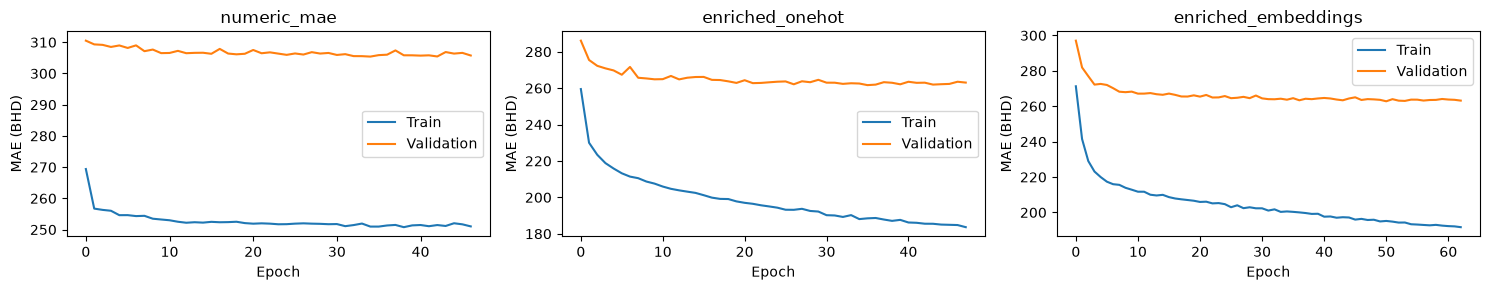

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, config in zip(axes, CONFIGS):
    hist = histories[config["name"]]
    ax.plot(hist["mae"] * TARGET_SCALE, label="Train")
    ax.plot(hist["val_mae"] * TARGET_SCALE, label="Validation")
    ax.set_title(config["name"])
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MAE (BHD)")
    ax.legend()
plt.tight_layout()
plt.show()

## 11. Held-out evaluation
After freezing the choice, evaluate all predefined candidates for the assignment's comparison table. No further tuning follows. All metrics use the same rows and original uncapped rents. The selected model is still the validation winner, even if another model happens to perform better here.

This holdout was already inspected in Version 2, so it is a reused benchmark, not a newly untouched test. Random splits also permit duplicate listings across sets. Only the competition can reveal the private leaderboard score.

In [12]:
holdout_inputs = transform_features(X.loc[holdout_idx], prep)
base_holdout = base_scaler.transform(base_x.loc[holdout_idx]).astype("float32")
doctor = keras.models.load_model(OUTPUT_DIR / "doctor_baseline.keras")
doctor_pred = doctor.predict(base_holdout, verbose=0).ravel()
score_rows = [{"model":"doctor_baseline_seeded", **regression_scores(y.loc[holdout_idx], doctor_pred)}]
holdout_preds = {}
for config in CONFIGS:
    model = keras.models.load_model(OUTPUT_DIR / (config["name"] + ".keras"))
    hi = inputs_for(config, holdout_inputs, base_holdout)
    pred = predict_bhd(model, hi[config["kind"]])
    holdout_preds[config["name"]] = pred
    score_rows.append({"model":config["name"], **regression_scores(y.loc[holdout_idx], pred)})
holdout_scores = pd.DataFrame(score_rows)
holdout_scores["selected_on_validation"] = holdout_scores["model"].eq(best_name)
holdout_scores.to_csv(OUTPUT_DIR / "holdout_comparison.csv", index=False)
display(holdout_scores)
selected_pred = holdout_preds[best_name]
selected_mae = mean_absolute_error(y.loc[holdout_idx], selected_pred)
baseline_mae = mean_absolute_error(y.loc[holdout_idx], doctor_pred)
print(f"Selected model: {best_name}; MAE = {selected_mae:.2f} BHD")
print(f"Change vs seeded doctor's baseline: {baseline_mae-selected_mae:.2f} BHD lower MAE")
print(f"Historical unseeded Version 2 MAE: 353.73 BHD (same rows/split, different neural initialization)")
embedding_val = comparison.set_index("model").loc["enriched_embeddings", "validation_MAE_BHD"]
onehot_val = comparison.set_index("model").loc["enriched_onehot", "validation_MAE_BHD"]
print(f"Embedding minus one-hot validation MAE: {embedding_val-onehot_val:.2f} BHD (negative favors embeddings)")

,model,MAE_BHD,RMSE_BHD,R2,selected_on_validation
0,doctor_baseline_seeded,313.478909,2687.138100,0.010894,False
1,numeric_mae,235.333635,2685.089459,0.012402,False
2,enriched_onehot,194.487507,2678.491928,0.017249,True
3,enriched_embeddings,195.712275,2679.157729,0.016760,False


Selected model: enriched_onehot; MAE = 194.49 BHD
Change vs seeded doctor's baseline: 118.99 BHD lower MAE
Historical unseeded Version 2 MAE: 353.73 BHD (same rows/split, different neural initialization)
Embedding minus one-hot validation MAE: 1.14 BHD (negative favors embeddings)


### Recorded run — interpretation (21 November 2026)
The validation-selected **enriched one-hot network** achieved **194.17 BHD holdout MAE**, compared with **312.39 BHD** for the seeded doctor baseline (37.8% lower). The embedding candidate achieved 195.68 BHD; its validation MAE was 0.60 BHD worse than one-hot. This single run therefore **does not support an accuracy advantage from embeddings**. It does use fewer parameters: 31,192 versus 71,041.

The numeric MAE candidate scored 235.55 BHD on the holdout. Its comparison with the doctor changes several settings together; do not attribute the difference solely to MAE loss. The enriched models then improve on that numerical-only candidate.

Twenty holdout listings above 3,000 BHD contribute about 567,099 BHD of total absolute error. The remaining 6,395 rows have 106.10 BHD MAE, but that restricted figure is **not** the full score. No rows are excluded from the reported 194.17 BHD result.

These results improve on Version 2 on the same split. Version 1's 144.39 BHD score used a different grouped split and population, so it cannot establish which version is better. The competition score is unknown and MAE below 70 has not been achieved locally. Numbers in this paragraph describe the saved run; if rerunning, use the newly executed tables as authoritative.

### Error analysis and interpretation
Inspect error by property type and target range after model selection. Range-restricted numbers are diagnostic only; the official local score includes every holdout row. A few extreme labels can dominate MAE, but we do not delete them to make the score look better.

In [13]:
errors = pd.DataFrame({"actual":y.loc[holdout_idx].to_numpy(), "prediction":selected_pred,
    "property_type":train.loc[holdout_idx, "property_type"].to_numpy()})
errors["absolute_error"] = abs(errors["actual"]-errors["prediction"])
display(errors.groupby("property_type")["absolute_error"].agg(["size", "mean"]).sort_values("size", ascending=False))
errors["rent_range"] = np.where(errors["actual"] <= 3000, "Up to 3000", "Above 3000")
display(errors.groupby("rent_range")["absolute_error"].agg(["size", "mean", "sum"]))
errors.to_csv(OUTPUT_DIR / "holdout_predictions.csv", index=False)

,size,mean
property_type,,
Apartment,4985,155.010304
Villa,1237,313.930875
Duplex,63,113.005422
Compound,56,217.849684
Penthouse,43,240.239233
Whole Building,11,4866.843500
Townhouse,10,149.504819
Hotel Apartment,5,160.375562
Bulk Rent Unit,3,205.117116


,size,mean,sum
rent_range,,,
Above 3000,20,28376.055704,567521.114075
Up to 3000,6395,106.351250,680116.241486


## 12. Final training and submission
Refit the selected model on all labeled rows with valid positive rents, including incomplete feature rows handled by imputation. This expands beyond the complete-case evaluation population; performance on those extra rows is not separately established.

Refit preprocessing using these labeled rows, then train for the validation-selected epoch count. Use one seed, matching the evaluated approach; no ensemble or further tuning is introduced. Competition test targets are never available.

In [14]:
final_y = pd.to_numeric(raw["rent"], errors="coerce")
valid = final_y.notna() & np.isfinite(final_y) & final_y.gt(0)
final_y = final_y.loc[valid]
final_X = engineer_features(raw.loc[valid])
final_prep = fit_preprocessor(final_X)
full_inputs = transform_features(final_X, final_prep)
comp_inputs = transform_features(competition_X, final_prep)
base_cols = list(base_x.columns)
final_medians = final_X[base_cols].median()
final_scaler = StandardScaler().fit(final_X[base_cols].fillna(final_medians))
final_numeric = final_scaler.transform(final_X[base_cols].fillna(final_medians)).astype("float32")
comp_numeric = final_scaler.transform(competition_X[base_cols].fillna(final_medians)).astype("float32")
fi = inputs_for(best_config, full_inputs, final_numeric)
ci = inputs_for(best_config, comp_inputs, comp_numeric)
keras.backend.clear_session()
final_model = build_network(best_config, fi, final_prep, final_y, SEED)
final_model.fit(make_dataset(fi[best_config["kind"]], final_y, training=True), epochs=best_epochs,
    callbacks=[TerminateOnNaN()], verbose=0)
final_prediction = predict_bhd(final_model, ci[best_config["kind"]])
final_model.save(OUTPUT_DIR / "final_model.keras")
joblib.dump({"preprocessor":final_prep, "base_medians":final_medians, "base_scaler":final_scaler,
             "config":best_config}, OUTPUT_DIR / "preprocessing.joblib")
print("Final training rows:", len(final_y), "Epochs:", best_epochs)

c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Final training rows: 32090 Epochs: 36


### Validate and export
Export exactly `Property_id,Rent`, in the actual competition test order. Check row count, IDs and finite nonnegative predictions. These checks confirm file integrity, not leaderboard performance.

In [17]:
submission = pd.DataFrame({"Property_id":test_raw["Property_id"], "Rent":final_prediction})
assert list(submission.columns) == ["Property_id", "Rent"]
assert len(submission) == len(test_raw)
assert submission["Property_id"].equals(test_raw["Property_id"])
assert submission["Property_id"].notna().all() and submission["Property_id"].is_unique
assert np.isfinite(submission["Rent"]).all() and submission["Rent"].ge(0).all()
submission.to_csv(OUTPUT_DIR / "submission_version3.csv", index=False)
metadata = {"selected_model":best_name, "epochs":best_epochs, "seed":SEED,
    "holdout_MAE_BHD":float(selected_mae), "seeded_doctor_MAE_BHD":float(baseline_mae),
    "tensorflow_version":tf.__version__, "test_rows":len(submission)}
(OUTPUT_DIR / "run_summary.json").write_text(json.dumps(metadata, indent=2))
display(submission.head())
print("Saved:", OUTPUT_DIR / "submission_version3.csv")

,Property_id,Rent
0,25c91c33-a523-42f2-8c10-9f340005471d,445.256256
1,6bcb7804-9cd7-4792-8cbe-abb4de65058a,226.314240
2,7b733e67-ec21-4427-95f8-4be3d9d18f6b,1059.534790
3,feefd51f-a7d6-45b0-a9eb-200d9f9821b4,387.716156
4,cca286dd-ddc6-41c2-9584-f8e17461220f,448.629395


Saved: version3_research_outputs\submission_version3.csv


## 13. What to explain to the doctor
- **Related work:** the 2023 rent paper motivates a normalized neural regression pipeline; the 2016 paper provides the categorical-embedding idea.
- **Our contribution:** adapt these ideas to Bahrain, add available property information, optimize the competition's MAE and run explicit controls.
- **Evidence:** use the executed validation and holdout tables above. If embeddings lose to one-hot, state that honestly. Better overall performance does not prove embeddings caused the entire gain.
- **Limits:** one dataset, one seed, reused random holdout, possible repeated listings, incomplete-row evaluation scope, and extreme labels. Different papers' errors are not directly comparable across markets, currencies or metrics.
- **Next research step:** repeat the one-hot/embedding comparison over several seeds and URL-grouped splits before claiming generalizable superiority. No leaderboard score is known until the CSV is submitted.

The bibliography and paper-to-code mapping are in Section 1. This notebook contains our original implementation; it does not reproduce the authors' reported experiments or promise MAE below 70.